In [ ]:
#--------------------------------------------------------------
## PREPROCESSING DVF — Sortie
#--------------------------------------------------------------

# dvf.to_csv("../data/processed/dvf_preprocessing.csv", sep=",",index=False) 

In [ ]:
#--------------------------------------------------------------
## PREPROCESSING DVF — Import Source
#--------------------------------------------------------------

import sys
import os
import pandas as pd
import numpy as np
sys.path.append(os.path.abspath(".."))

from src.features.build_features_enrichi import (
    creer_features_enrichi,
    detecter_prix_extremes,
    ajouter_historique_parcelle,
    ajouter_historique_voie,
    ajouter_marche_local_historique,
    ajouter_comparables,
    ajouter_features_equipements_osm,
    finaliser_datasets,
    finaliser_experience,
)

dvf = pd.read_csv("../data/processed/dvf_preprocessing.csv", sep=",") 

print("DVF preprocessed:", dvf.shape)

# dvf.iloc[:,10].map(type).value_counts()


In [4]:
#------------------------------------------------------------
## E0 — BASELINE ENRICHIE : DVF + features BASELINE + ajout intial features enrichies
#------------------------------------------------------------

dvf_initial_features_enrichies = creer_features_enrichi(dvf)
display(dvf_initial_features_enrichies.head())

dvf_nettoye_features_enrichies, valeurs_extremes, tableau_seuils = detecter_prix_extremes(dvf_initial_features_enrichies)

display(tableau_seuils)
print("Nombre de lignes avant filtrage :", len(dvf))
print("Nombre de lignes après filtrage :", len(dvf_nettoye_features_enrichies))
print("Nombre de valeurs extrêmes :", len(valeurs_extremes))

assert len(dvf) == len(dvf_initial_features_enrichies)

# Finalisation et export des deux datasets
dvf_initial_final, dvf_nettoye_final = finaliser_datasets(dvf_initial_features_enrichies, dvf_nettoye_features_enrichies)

# E0 est écrit ici UNE SEULE FOIS et ne sera plus écrasé.
dvf_nettoye_final.to_csv("../data/processed/dvf_nettoye_features_enrichies.csv", index=False)
print("\nSortie finale jeu de donnée Baseline E0 : (après traitement 'colonnes_a_supprimer' finaliser_datasets())")
display(dvf_nettoye_final.head())

print("Baseline E0 exportée :", dvf_nettoye_final.shape)


,id_mutation,date_mutation,valeur_fonciere,adresse_numero,adresse_nom_voie,adresse_code_voie,code_postal,code_commune,nom_commune,id_parcelle,...,has_lot,surface_carrez_totale,has_carrez,carrez_bati_ratio,ecart_carrez_bati,has_nature_culture,nature_jardin,nature_terrain_agrement,has_code_voie,distance_lyon_km
0,2021-1131719,2021-01-05,375000.0,46.0,RUE DOC ALBERIC PONT,2193,69005,69385,Lyon 5e Arrondissement,69385000BO0189,...,1,98.86,1,0.91537,-9.14,0,0,0,1,3.164923
1,2021-1131721,2021-01-04,203050.0,10.0,AV DE MENIVAL,4720,69005,69385,Lyon 5e Arrondissement,69385000BC0024,...,1,NaN,0,NaN,NaN,0,0,0,1,3.929888
2,2021-1131723,2021-01-04,140000.0,250.0,RUE DES ERABLES,2530,69009,69389,Lyon 9e Arrondissement,69389000AS0091,...,1,NaN,0,NaN,NaN,0,0,0,1,3.741073
3,2021-1131724,2021-01-04,174100.0,54.0,RUE PIERRE AUDRY,5450,69009,69389,Lyon 9e Arrondissement,69389000CD0032,...,1,69.63,1,1.00913,0.63,0,0,0,1,2.291661
4,2021-1131726,2021-01-07,470250.0,21.0,RUE DES CEDRES,0022,69650,69207,Saint-Germain-au-Mont-d'Or,69207000AO0092,...,0,NaN,0,NaN,NaN,1,0,0,1,13.015311


,Type,Borne basse (€/m²),Borne haute (€/m²),Nombre total,Valeurs extrêmes
0,Appartement,1334.868278,10681.433087,83162,2315
1,Maison,1148.531697,11437.473734,31944,1902


Nombre de lignes avant filtrage : 115106
Nombre de lignes après filtrage : 110889
Nombre de valeurs extrêmes : 4217

--- dvf_initial_features_enrichies ---
Dimensions : (115106, 33)
Fichier : ../data/processed/dvf_initial_features_enrichies.csv

--- dvf_nettoye_features_enrichies ---
Dimensions : (110889, 33)
Fichier : ../data/processed/dvf_nettoye_features_enrichies.csv

Sortie finale jeu de donnée Baseline E0 : (après traitement 'colonnes_a_supprimer' finaliser_datasets())


,date_mutation,valeur_fonciere,code_commune,lot1_surface_carrez,nombre_lots,type_local,surface_reelle_bati,nombre_pieces_principales,surface_terrain,longitude,...,has_lot,surface_carrez_totale,has_carrez,carrez_bati_ratio,ecart_carrez_bati,has_nature_culture,nature_jardin,nature_terrain_agrement,has_code_voie,distance_lyon_km
0,2021-01-05,375000.0,69385,98.86,2,Appartement,108.0,5.0,NaN,4.797315,...,1,98.86,1,0.91537,-9.14,0,0,0,1,3.164923
1,2021-01-04,203050.0,69385,NaN,2,Appartement,83.0,5.0,NaN,4.786061,...,1,NaN,0,NaN,NaN,0,0,0,1,3.929888
2,2021-01-04,140000.0,69389,NaN,2,Appartement,73.0,3.0,NaN,4.795657,...,1,NaN,0,NaN,NaN,0,0,0,1,3.741073
3,2021-01-04,174100.0,69389,69.63,1,Appartement,69.0,3.0,NaN,4.806255,...,1,69.63,1,1.00913,0.63,0,0,0,1,2.291661
4,2021-01-07,470250.0,69207,NaN,0,Maison,121.0,5.0,705.0,4.807607,...,0,NaN,0,NaN,NaN,1,0,0,1,13.015311


Baseline E0 exportée : (110889, 33)


In [5]:
#------------------------------------------------------------
## JOINTURE : DVF features enrichi + Insee
#------------------------------------------------------------

import pandas as pd

# 1. CHARGEMENT DES DONNÉES
# ============================================================

df_dvf_enrichies = dvf_nettoye_features_enrichies.copy().drop('lot1_numero', axis=1, errors='ignore')

df_insee = pd.read_csv("../data/processed/insee_comparateur_territoires_69.csv")

print("Dimensions DVF :", df_dvf_enrichies.shape)
print("Dimensions INSEE :", df_insee.shape)


# ============================================================
# 2. VÉRIFICATION DU CODE COMMUNE
# ============================================================

print("\nType code_commune DVF :", df_dvf_enrichies["code_commune"].dtype)
print("Type code_commune INSEE :", df_insee["code_commune"].dtype)

# Harmonisation pour sécuriser la jointure
df_dvf_enrichies["code_commune"] = df_dvf_enrichies["code_commune"].astype(str).str.zfill(5)
df_insee["code_commune"] = df_insee["code_commune"].astype(str).str.zfill(5)


# ============================================================
# 3. VÉRIFICATION DES COMMUNES
# ============================================================

communes_dvf = set(df_dvf_enrichies["code_commune"].unique())
communes_insee = set(df_insee["code_commune"].unique())

print("\nNombre de communes DVF :", len(communes_dvf))
print("Nombre de communes INSEE :", len(communes_insee))

communes_absentes = communes_dvf - communes_insee

print("Communes DVF absentes de l'INSEE :", communes_absentes)

print("\n lot1_numero dans df_dvf_enrichies Av :","lot1_numero" in df_dvf_enrichies.columns)
print(" lot1_numero dans df_insee Av:", "lot1_numero" in df_insee.columns)

# ============================================================
# 4. JOINTURE DVF + INSEE
# ============================================================

df_dvf_enrichies_insee = df_dvf_enrichies.merge(
    df_insee,
    on="code_commune",
    how="left",
    indicator=True
)

print("\nDimensions avant jointure :", df_dvf_enrichies.shape)
print("Dimensions après jointure :", df_dvf_enrichies_insee.shape)

print("\nRésultat de la jointure :")
print(df_dvf_enrichies_insee["_merge"].value_counts())

print("\n lot1_numero dans df_dvf_enrichies AP :","lot1_numero" in df_dvf_enrichies.columns)
print(" lot1_numero dans df_insee AP:", "lot1_numero" in df_insee.columns)

# ============================================================
# 5. CONTRÔLE DES VALEURS MANQUANTES INSEE
# ============================================================

colonnes_insee = [
    "niveau_vie_median",
    "population",
    "superficie_km2",
    "nb_etablissements",
    "densite_population",
    "part_proprietaires",
    "part_logements_vacants"
]

print("\nValeurs manquantes après jointure :")
print(df_dvf_enrichies_insee[colonnes_insee].isna().sum())


# Suppression de la colonne technique de jointure
df_dvf_enrichies_insee = df_dvf_enrichies_insee.drop(columns="_merge")

# Aperçu du dataset enrichi
display(df_dvf_enrichies_insee.head())

# Sortie E0 : Baseline E0 + jointure insee (après traitement 'colonnes_a_supprimer' finaliser_experience())
finaliser_experience(
    df_dvf_enrichies_insee, 
    "../data/processed/dvf_features_enrichies_insee.csv"
)

print("Baseline E0 + Jointure INSEE exportée :", df_dvf_enrichies_insee.shape)

Dimensions DVF : (110889, 41)
Dimensions INSEE : (275, 13)

Type code_commune DVF : int64
Type code_commune INSEE : int64

Nombre de communes DVF : 276
Nombre de communes INSEE : 275
Communes DVF absentes de l'INSEE : {'69159', '69152'}

 lot1_numero dans df_dvf_enrichies Av : False
 lot1_numero dans df_insee Av: False

Dimensions avant jointure : (110889, 41)
Dimensions après jointure : (110889, 54)

Résultat de la jointure :
_merge
both          110304
left_only        585
right_only         0
Name: count, dtype: int64

 lot1_numero dans df_dvf_enrichies AP : False
 lot1_numero dans df_insee AP: False

Valeurs manquantes après jointure :
niveau_vie_median         587
population                585
superficie_km2            585
nb_etablissements         585
densite_population        585
part_proprietaires        585
part_logements_vacants    585
dtype: int64


,id_mutation,date_mutation,valeur_fonciere,adresse_numero,adresse_nom_voie,adresse_code_voie,code_postal,code_commune,nom_commune,id_parcelle,...,nb_proprietaires,nb_residences_secondaires,nb_logements_vacants,niveau_vie_median,population,superficie_km2,nb_etablissements,densite_population,part_proprietaires,part_logements_vacants
0,2021-1131719,2021-01-05,375000.0,46.0,RUE DOC ALBERIC PONT,2193,69005,69385,Lyon 5e Arrondissement,69385000BO0189,...,10216.77721,977.61046,2123.78484,29330.0,47777.0,6.23,1347.0,7668.860353,44.071008,8.080164
1,2021-1131721,2021-01-04,203050.0,10.0,AV DE MENIVAL,4720,69005,69385,Lyon 5e Arrondissement,69385000BC0024,...,10216.77721,977.61046,2123.78484,29330.0,47777.0,6.23,1347.0,7668.860353,44.071008,8.080164
2,2021-1131723,2021-01-04,140000.0,250.0,RUE DES ERABLES,2530,69009,69389,Lyon 9e Arrondissement,69389000AS0091,...,8781.48239,1475.41003,3395.54741,24160.0,53567.0,7.25,2471.0,7388.551724,33.308790,10.871034
3,2021-1131724,2021-01-04,174100.0,54.0,RUE PIERRE AUDRY,5450,69009,69389,Lyon 9e Arrondissement,69389000CD0032,...,8781.48239,1475.41003,3395.54741,24160.0,53567.0,7.25,2471.0,7388.551724,33.308790,10.871034
4,2021-1131726,2021-01-07,470250.0,21.0,RUE DES CEDRES,0022,69650,69207,Saint-Germain-au-Mont-d'Or,69207000AO0092,...,720.30245,19.43445,55.76842,30040.0,3124.0,5.43,64.0,575.322284,55.103465,4.034219


Export expérience : ../data/processed/dvf_features_enrichies_insee.csv
Dimensions : (110889, 45)
Baseline E0 + Jointure INSEE exportée : (110889, 53)


In [6]:
#------------------------------------------------------------
## E1 —  E0 + HISTORIQUE PARCELLE
#------------------------------------------------------------

experience_parcelle = ajouter_historique_parcelle(df_dvf_enrichies_insee)

print("E1 terminée :", experience_parcelle.shape)
display(experience_parcelle[[
    "previous_price_m2", 
    "years_since_previous_sale", 
    "parcel_transaction_count", 
    "parcel_price_growth" 
    ]].describe()
)

# Sortie E1 : E0 insee + historique_parcelle (après traitement 'colonnes_a_supprimer' finaliser_experience())
experience_parcelle_final = finaliser_experience(
    experience_parcelle,
    "../data/processed/experience_plus_historique_parcelle.csv"
)

print("Export E1 terminé.")


E1 terminée : (110889, 58)


,previous_price_m2,years_since_previous_sale,parcel_transaction_count,parcel_price_growth
count,65512.000000,65512.000000,110889.000000,52762.000000
mean,4021.763476,0.543966,5.344912,0.028060
std,1416.532835,0.732718,11.376851,0.291259
min,1169.382353,0.002738,0.000000,-0.842434
25%,2989.690722,0.084873,0.000000,-0.126996
50%,3914.893617,0.254620,1.000000,-0.004924
75%,4896.773098,0.684463,6.000000,0.133006
max,11294.117647,4.933607,176.000000,5.984127


Export expérience : ../data/processed/experience_plus_historique_parcelle.csv
Dimensions : (110889, 49)
Export E1 terminé.


In [7]:
#------------------------------------------------------------
## E2 — E1 + HISTORIQUE VOIE
#------------------------------------------------------------

experience_parcelle_voie = ajouter_historique_voie(experience_parcelle)

print("E2 terminée :", experience_parcelle_voie.shape)

# Sortie E2 : E1 + historique_voie (après traitement 'colonnes_a_supprimer' finaliser_experience())
experience_parcelle_voie_final = finaliser_experience(
    experience_parcelle_voie,
    "../data/processed/experience_plus_historique_parcelle_voie.csv"
)

print("Export E2 terminé.")


E2 terminée : (110889, 60)
Export expérience : ../data/processed/experience_plus_historique_parcelle_voie.csv
Dimensions : (110889, 51)
Export E2 terminé.


In [8]:
#------------------------------------------------------------
## E3 — E2 + MARCHÉ LOCAL HISTORIQUE
#------------------------------------------------------------

experience_parcelle_voie_marche = ajouter_marche_local_historique(experience_parcelle_voie)

print("E3 terminée :", experience_parcelle_voie_marche.shape)

# Sortie E3 : E2 + marche_local_historique (après traitement 'colonnes_a_supprimer' finaliser_experience())
experience_parcelle_voie_marche_final = finaliser_experience(
    experience_parcelle_voie_marche,
    "../data/processed/experience_plus_historique_parcelle_voie_marche_local.csv"
)

print("Export E3 terminé.")


E3 terminée : (110889, 62)
Export expérience : ../data/processed/experience_plus_historique_parcelle_voie_marche_local.csv
Dimensions : (110889, 53)
Export E3 terminé.


In [9]:
#------------------------------------------------------------
## E4 — + TRANSACTIONS COMPARABLES
#------------------------------------------------------------

experience_complete = ajouter_comparables(experience_parcelle_voie_marche)

print("E4 terminée :", experience_complete.shape)

# Sortie E4 : E3 + comparables (après traitement 'colonnes_a_supprimer' finaliser_experience())
experience_complete_final = finaliser_experience(
    experience_complete,
    "../data/processed/experience_plus_historique_parcelle_voie_marche_local_comparables.csv"
)

print("Export E4 terminé.")


E4 terminée : (110889, 64)
Export expérience : ../data/processed/experience_plus_historique_parcelle_voie_marche_local_comparables.csv
Dimensions : (110889, 55)
Export E4 terminé.


In [ ]:
#------------------------------------------------------------
## CONTRÔLES FINAUX DES NOUVELLES FEATURES
#------------------------------------------------------------

familles = {
    "Historique parcelle": [
        "previous_price_m2",
        "previous_sale_date",
        "years_since_previous_sale",
        "parcel_transaction_count",
        "parcel_price_growth",
    ],
    "Historique voie": [
        "street_previous_median_price_m2",
        "street_previous_transaction_count",
    ],
    "Marché local": [c for c in experience_complete.columns
        if c.startswith("local_median_price_m2_")
        or c.startswith("local_transaction_count_")
    ],
    "Comparables": [
        "comparable_median_price_m2",
        "comparable_count",
    ],
}

for nom, colonnes in familles.items():
    presentes = [c for c in colonnes if c in experience_complete.columns]
    print(f"\n{nom} : {len(presentes)} variables")
    if presentes:
        resultats = []

        for c in presentes:
            taux_na = round(experience_complete[c].isna().mean() * 100, 2)
            nb_valeurs = experience_complete[c].nunique(dropna=True)
            resultats.append({"variable": c, "taux_NA_%": taux_na, "valeurs_distinctes": nb_valeurs})

        tableau_controle = pd.DataFrame(resultats)
        display(tableau_controle)

print("\nE0 -> E4 terminées.")



Historique parcelle : 5 variables


,variable,taux_NA_%,valeurs_distinctes
0,previous_price_m2,40.92,33525
1,previous_sale_date,40.92,1344
2,years_since_previous_sale,40.92,1601
3,parcel_transaction_count,0.00,175
4,parcel_price_growth,52.42,49860



Historique voie : 2 variables


,variable,taux_NA_%,valeurs_distinctes
0,street_previous_median_price_m2,2.47,29740
1,street_previous_transaction_count,0.00,803



Marché local : 0 variables

Comparables : 2 variables


,variable,taux_NA_%,valeurs_distinctes
0,comparable_median_price_m2,3.63,26948
1,comparable_count,0.00,2733



E0 -> E4 terminées.


In [ ]:
#------------------------------------------------------------
## A0 — E4 + ÉQUIPEMENTS OSM
#------------------------------------------------------------

# Chargement du snapshot OSM utilisé pour l'enrichissement
osm = pd.read_csv("../data/raw/osm_69_2025_preprocessed.csv", low_memory=False)

# Ajout des équipements OSM au dataset E4 nettoyé
experience_complete_osm = ajouter_features_equipements_osm(experience_complete, osm)

print("E4 + OSM :", experience_complete_osm.shape)

colonnes_osm = [
    "creches_500m",
    "ecoles_500m",
    "commerces_essentiels_500m",
    "restaurants_500m",
    "sante_500m",
    "transports_500m",
    "sports_loisirs_500m",
    "espaces_verts_500m",
    "distance_creches_min",
    "distance_ecoles_min",
    "distance_transports_min",
    "distance_commerces_essentiels_min",
    "distance_espaces_verts_min"
    ]

display(experience_complete_osm[colonnes_osm].describe())

# Sortie A0 : E4 + ÉQUIPEMENTS OSM (après traitement 'colonnes_a_supprimer' finaliser_experience())
experience_complete_osm_final = finaliser_experience(
    experience_complete_osm,
    "../data/processed/dvf_nettoye_features_enrichies_osm.csv"
)

print("Export E4 + OSM terminé.")


E4 + OSM : (110889, 77)


,creches_500m,ecoles_500m,commerces_essentiels_500m,restaurants_500m,sante_500m,transports_500m,sports_loisirs_500m,espaces_verts_500m,distance_creches_min,distance_ecoles_min,distance_transports_min,distance_commerces_essentiels_min,distance_espaces_verts_min
count,109064.000000,109064.000000,109064.000000,109064.000000,109064.000000,109064.000000,109064.000000,109064.000000,109064.000000,109064.000000,109064.000000,109064.000000,109064.000000
mean,0.059470,0.424512,0.625477,1.172578,0.512048,3.581833,0.970146,0.609358,7157.932652,5845.767750,4523.845879,5705.692846,5305.513401
std,0.332096,1.425523,2.527428,6.311853,2.469469,13.190037,3.346223,2.158321,3590.500432,3587.192474,3074.002006,3483.603697,3276.661823
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.168626,0.153837,0.124210,1.206412,4.247932
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4481.677797,2369.025698,1407.016224,2412.955247,2251.701575
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7995.929424,6685.494866,5054.950286,6548.892680,5969.716844
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9783.974339,8965.148537,7149.265250,8739.417122,8108.312143
max,6.000000,14.000000,26.000000,84.000000,43.000000,138.000000,204.000000,25.000000,30247.385610,12046.340490,11498.582808,11999.810998,11865.183685


Export expérience : ../data/processed/dvf_nettoye_features_enrichies_osm.csv
Dimensions : (110889, 68)
Export E4 + OSM terminé.


### DataViz OSM

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import sys
sys.path.append(os.path.abspath("..")) 


df = pd.read_csv("../data/processed/dvf_nettoye_features_enrichies_osm.csv", low_memory=False)

# Préparer les colonnes utilisées dans les analyses
df["date_mutation"] = pd.to_datetime(df["date_mutation"], errors="coerce")

for col in ["prix_m2", "latitude", "longitude"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df["type_local"] = df["type_local"].astype("string").fillna("Non renseigné")
df["code_commune"] = df["code_commune"].astype("string").fillna("Non renseignée")

# Garder les transactions avec un prix au m² positif et exploitable
df_viz = df.dropna(subset=["prix_m2"]).copy()
prix_valide = np.isfinite(df_viz["prix_m2"]) & (df_viz["prix_m2"] > 0)
df_viz = df_viz[prix_valide]

print("Dimensions :", df.shape)
print("Transactions avec prix au m² exploitable :", len(df_viz))
print("Période :", df["date_mutation"].min(), "→", df["date_mutation"].max())
print("Types de biens :", df["type_local"].value_counts().to_dict())

#### Couverture des équipements OpenStreetMap

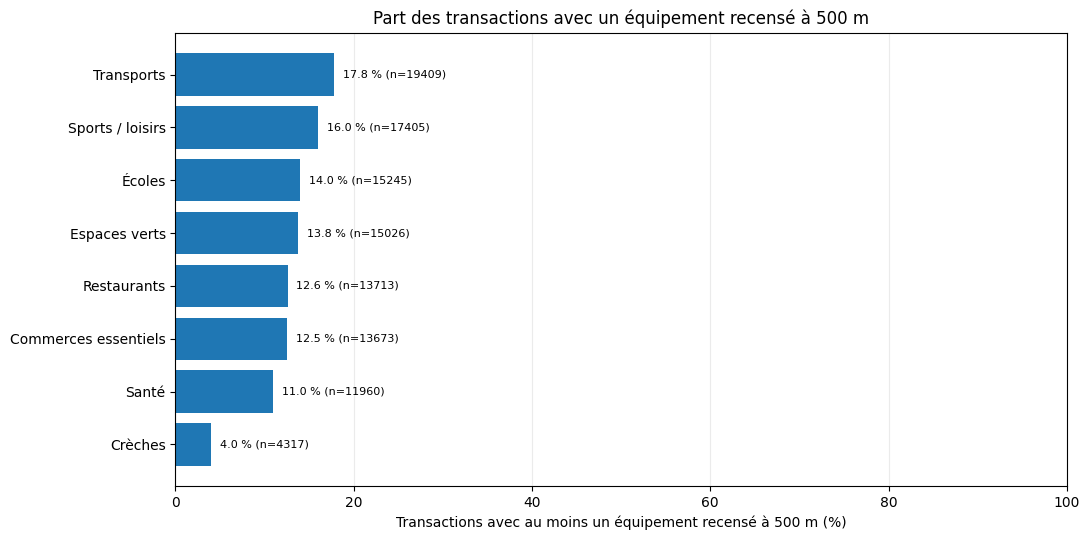

In [ ]:
osm_counts = {
    "Crèches": "creches_500m",
    "Écoles": "ecoles_500m",
    "Commerces essentiels": "commerces_essentiels_500m",
    "Restaurants": "restaurants_500m",
    "Santé": "sante_500m",
    "Transports": "transports_500m",
    "Sports / loisirs": "sports_loisirs_500m",
    "Espaces verts": "espaces_verts_500m",
}

rows = []

for categorie, colonne in osm_counts.items():
    comptage = pd.to_numeric(df[colonne], errors="coerce")
    connus = comptage.dropna()
    total = len(connus)
    avec_equipement = (connus > 0).sum()

    rows.append({
        "Catégorie": categorie,
        "Part avec équipement (%)": 100 * avec_equipement / total,
        "Transactions avec équipement": avec_equipement,
    })

osm_resume = pd.DataFrame(rows).sort_values("Part avec équipement (%)")

fig, ax = plt.subplots(figsize=(11, 5.5))

barres = ax.barh(
    osm_resume["Catégorie"],
    osm_resume["Part avec équipement (%)"]
)

ax.set_xlim(0, 100)
ax.set_xlabel("Transactions avec au moins un équipement recensé à 500 m (%)")
ax.set_title("Part des transactions avec un équipement recensé à 500 m")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

for barre, pourcentage, effectif in zip(
    barres,
    osm_resume["Part avec équipement (%)"],
    osm_resume["Transactions avec équipement"]
):
    ax.text(
        pourcentage + 1,
        barre.get_y() + barre.get_height() / 2,
        f"{pourcentage:.1f} % (n={int(effectif)})",
        va="center",
        fontsize=8
    )

plt.tight_layout()
plt.show()